In [ ]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore Warnings
import warnings
warnings.filterwarnings('ignore')

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

In [ ]:
df = pd.read_csv('/content/heart_cleveland_upload.csv')

In [ ]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0


In [ ]:
print("Rows and Columns:", df.shape)

Rows and Columns: (297, 14)


In [ ]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'condition'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        297 non-null    int64  
 1   sex        297 non-null    int64  
 2   cp         297 non-null    int64  
 3   trestbps   297 non-null    int64  
 4   chol       297 non-null    int64  
 5   fbs        297 non-null    int64  
 6   restecg    297 non-null    int64  
 7   thalach    297 non-null    int64  
 8   exang      297 non-null    int64  
 9   oldpeak    297 non-null    float64
 10  slope      297 non-null    int64  
 11  ca         297 non-null    int64  
 12  thal       297 non-null    int64  
 13  condition  297 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 32.6 KB


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,297.0,54.542088,9.049736,29.0,48.0,56.0,61.0,77.0
sex,297.0,0.676768,0.468500,0.0,0.0,1.0,1.0,1.0
cp,297.0,2.158249,0.964859,0.0,2.0,2.0,3.0,3.0
trestbps,297.0,131.693603,17.762806,94.0,120.0,130.0,140.0,200.0
chol,297.0,247.350168,51.997583,126.0,211.0,243.0,276.0,564.0
fbs,297.0,0.144781,0.352474,0.0,0.0,0.0,0.0,1.0
restecg,297.0,0.996633,0.994914,0.0,0.0,1.0,2.0,2.0
thalach,297.0,149.599327,22.941562,71.0,133.0,153.0,166.0,202.0
exang,297.0,0.326599,0.469761,0.0,0.0,0.0,1.0,1.0
oldpeak,297.0,1.055556,1.166123,0.0,0.0,0.8,1.6,6.2


In [ ]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [ ]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


#Identifying Features

In [ ]:
# Target Variable
target = 'condition'

# Predictor Variables
X = df.drop(columns=target)

# Target Variable
y = df[target]

print("Features Shape :", X.shape)
print("Target Shape :", y.shape)

Features Shape : (297, 13)
Target Shape : (297,)


In [ ]:
numerical_features = [
    'age',
    'trestbps',
    'chol',
    'thalach',
    'oldpeak'
]

categorical_features = [
    'sex',
    'cp',
    'fbs',
    'restecg',
    'exang',
    'slope',
    'ca',
    'thal'
]

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical Features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


In [ ]:
print("Total Features :", len(X.columns))
print("Numerical Features :", len(numerical_features))
print("Categorical Features :", len(categorical_features))

Total Features : 13
Numerical Features : 5
Categorical Features : 8


In [ ]:
df['condition'].value_counts()

,count
condition,
0,160
1,137


In [ ]:
round(df['condition'].value_counts(normalize=True)*100,2)

,proportion
condition,
0,53.87
1,46.13


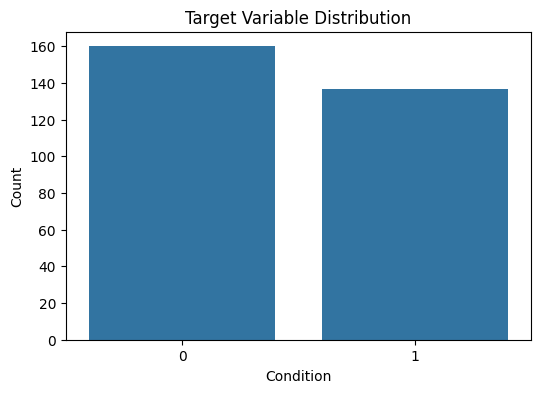

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))

sns.countplot(x='condition', data=df)

plt.title("Target Variable Distribution")
plt.xlabel("Condition")
plt.ylabel("Count")

plt.show()

#Feature Understanding.

#Numerical Features


Feature 1


In [ ]:
print(df['age'].describe())

count    297.000000
mean      54.542088
std        9.049736
min       29.000000
25%       48.000000
50%       56.000000
75%       61.000000
max       77.000000
Name: age, dtype: float64


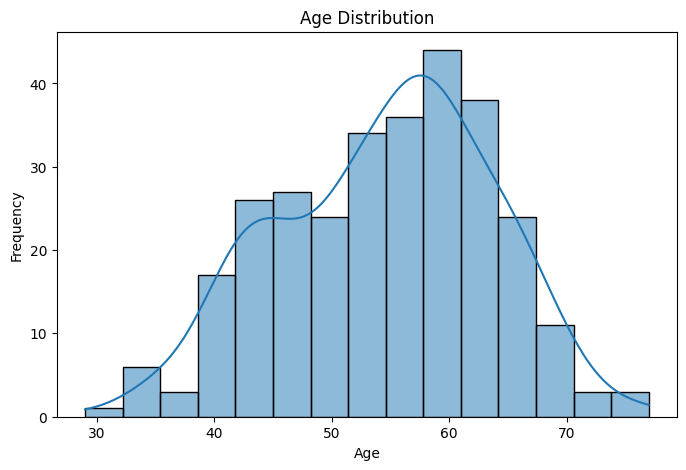

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['age'], bins=15, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

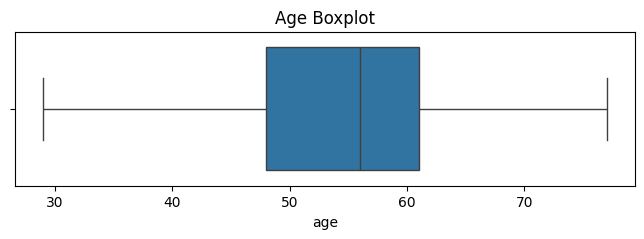

In [ ]:
plt.figure(figsize=(8,2))

sns.boxplot(x=df['age'])

plt.title("Age Boxplot")

plt.show()

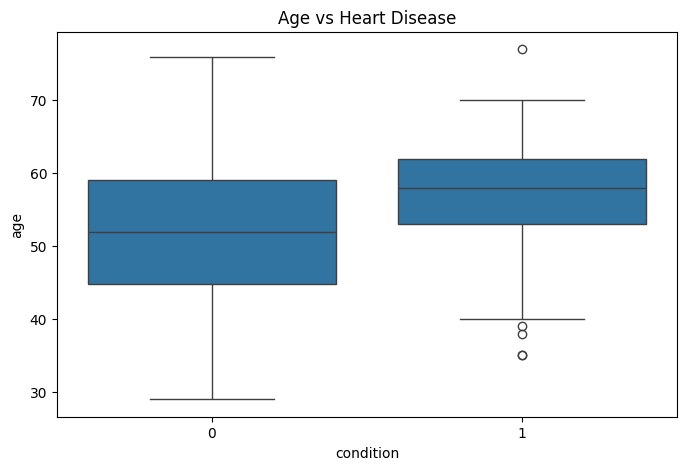

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x='condition', y='age', data=df)

plt.title("Age vs Heart Disease")

plt.show()

Feature 2

In [ ]:
print(df['trestbps'].describe())

count    297.000000
mean     131.693603
std       17.762806
min       94.000000
25%      120.000000
50%      130.000000
75%      140.000000
max      200.000000
Name: trestbps, dtype: float64


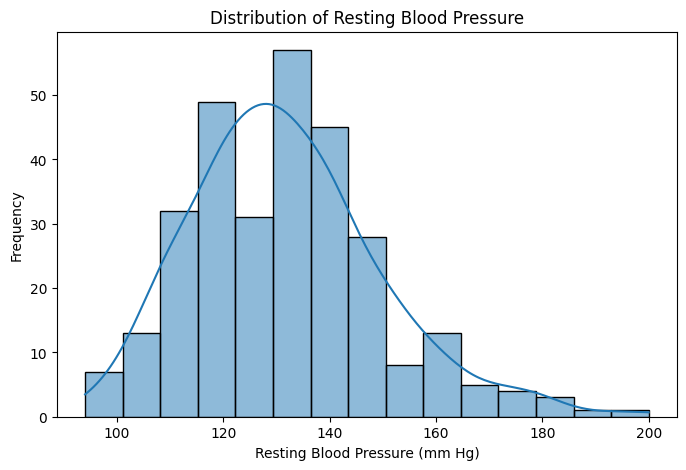

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['trestbps'], bins=15, kde=True)

plt.title("Distribution of Resting Blood Pressure")
plt.xlabel("Resting Blood Pressure (mm Hg)")
plt.ylabel("Frequency")

plt.show()

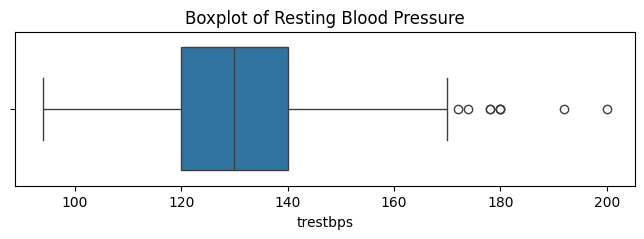

In [ ]:
plt.figure(figsize=(8,2))

sns.boxplot(x=df['trestbps'])

plt.title("Boxplot of Resting Blood Pressure")

plt.show()

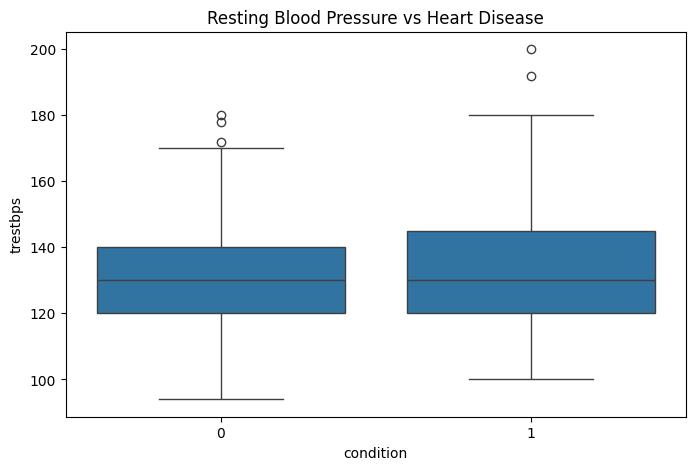

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x='condition', y='trestbps', data=df)

plt.title("Resting Blood Pressure vs Heart Disease")

plt.show()

Feature 3

In [ ]:
print(df['chol'].describe())

count    297.000000
mean     247.350168
std       51.997583
min      126.000000
25%      211.000000
50%      243.000000
75%      276.000000
max      564.000000
Name: chol, dtype: float64


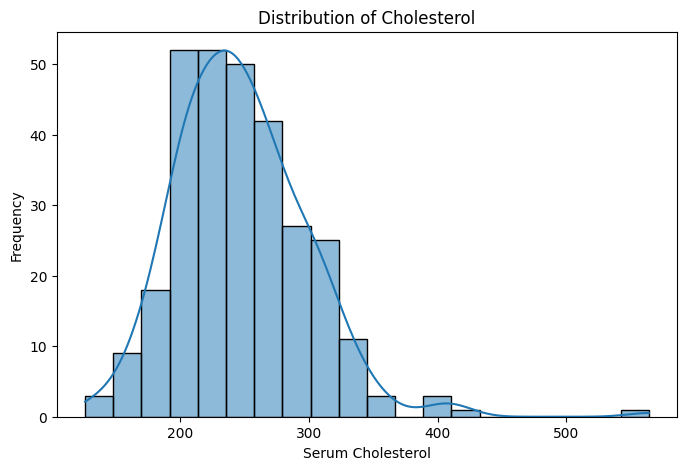

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['chol'], bins=20, kde=True)

plt.title("Distribution of Cholesterol")
plt.xlabel("Serum Cholesterol")
plt.ylabel("Frequency")

plt.show()

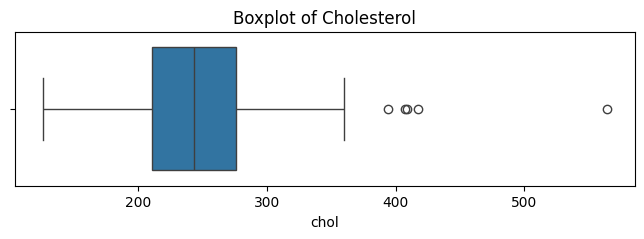

In [ ]:
plt.figure(figsize=(8,2))

sns.boxplot(x=df['chol'])

plt.title("Boxplot of Cholesterol")

plt.show()

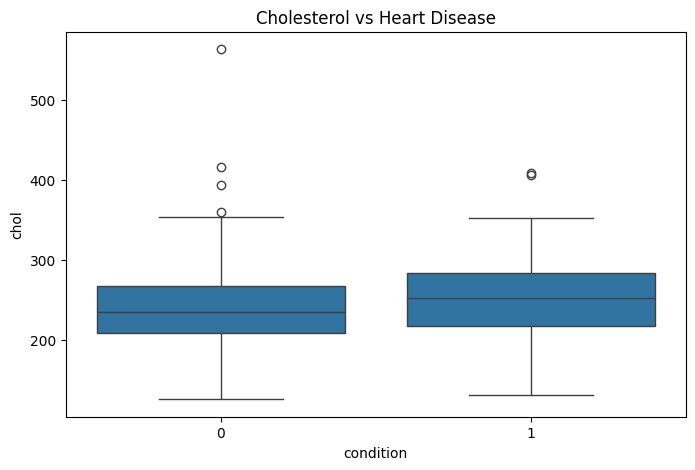

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x='condition', y='chol', data=df)

plt.title("Cholesterol vs Heart Disease")

plt.show()

In [ ]:
print(df['thalach'].describe())

count    297.000000
mean     149.599327
std       22.941562
min       71.000000
25%      133.000000
50%      153.000000
75%      166.000000
max      202.000000
Name: thalach, dtype: float64


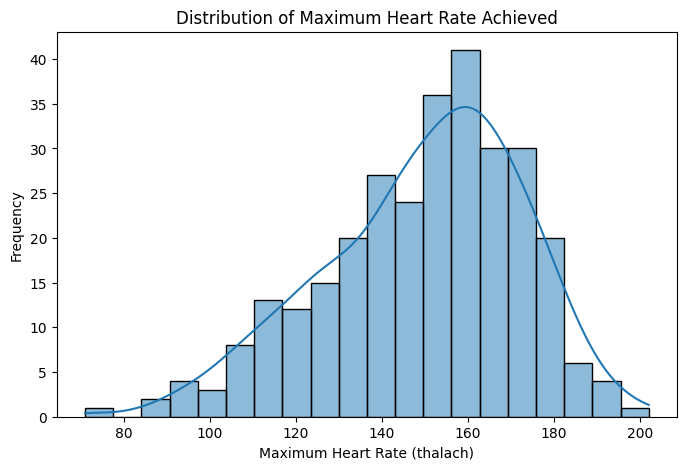

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['thalach'], bins=20, kde=True)

plt.title('Distribution of Maximum Heart Rate Achieved')
plt.xlabel('Maximum Heart Rate (thalach)')
plt.ylabel('Frequency')

plt.show()

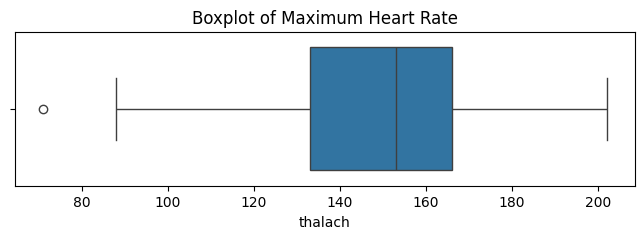

In [ ]:
plt.figure(figsize=(8,2))

sns.boxplot(x=df['thalach'])

plt.title('Boxplot of Maximum Heart Rate')

plt.show()

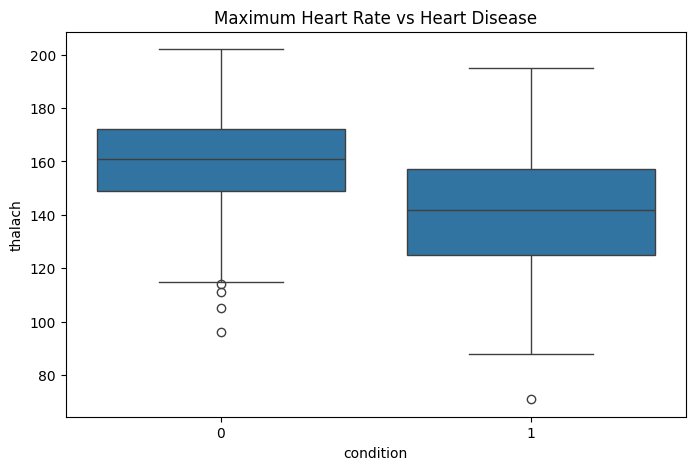

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x='condition', y='thalach', data=df)

plt.title('Maximum Heart Rate vs Heart Disease')

plt.show()

In [ ]:
print(df['oldpeak'].describe())

count    297.000000
mean       1.055556
std        1.166123
min        0.000000
25%        0.000000
50%        0.800000
75%        1.600000
max        6.200000
Name: oldpeak, dtype: float64


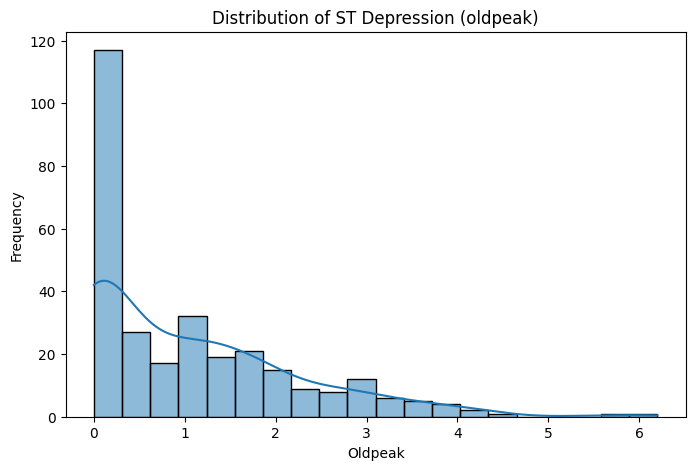

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['oldpeak'], bins=20, kde=True)

plt.title("Distribution of ST Depression (oldpeak)")
plt.xlabel("Oldpeak")
plt.ylabel("Frequency")

plt.show()

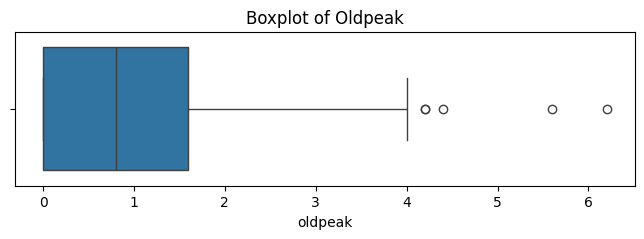

In [ ]:
plt.figure(figsize=(8,2))

sns.boxplot(x=df['oldpeak'])

plt.title("Boxplot of Oldpeak")

plt.show()

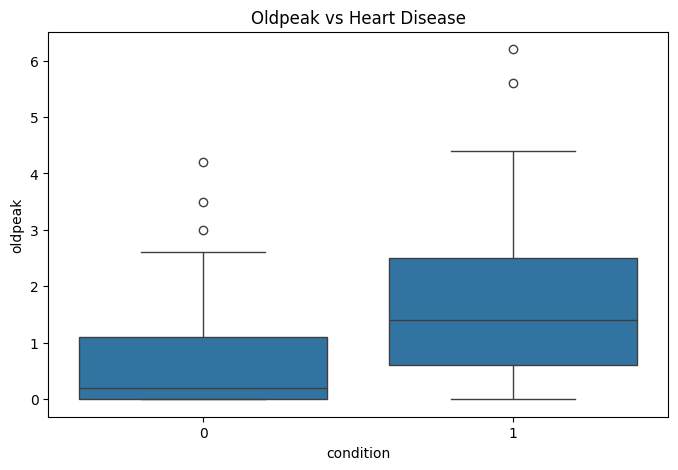

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x='condition', y='oldpeak', data=df)

plt.title("Oldpeak vs Heart Disease")

plt.show()

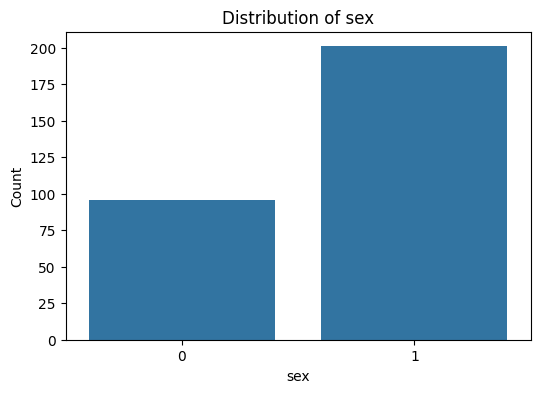

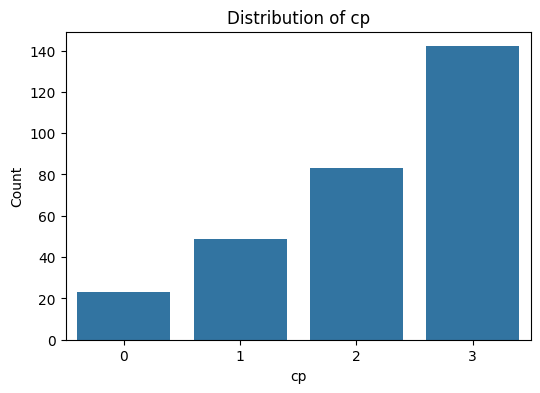

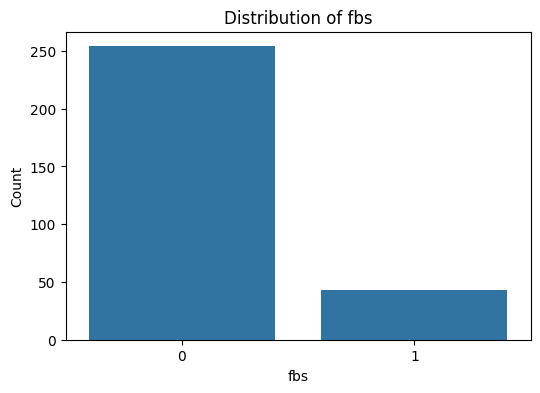

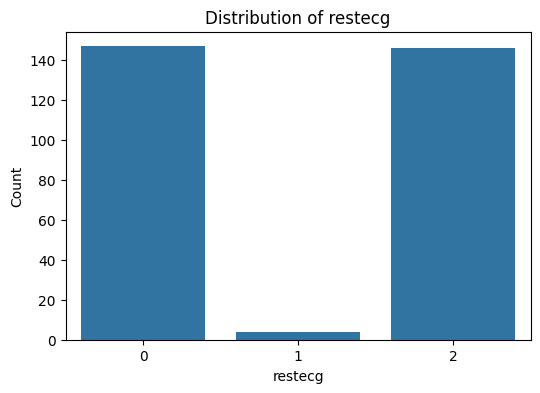

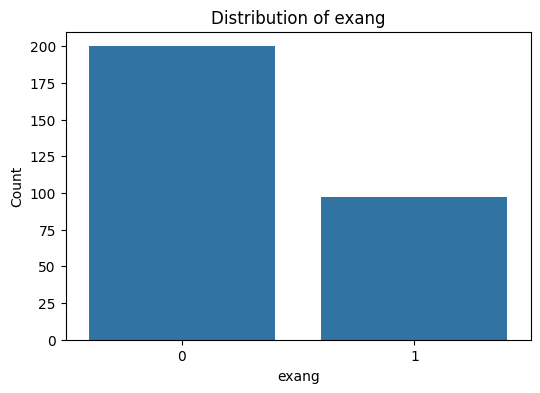

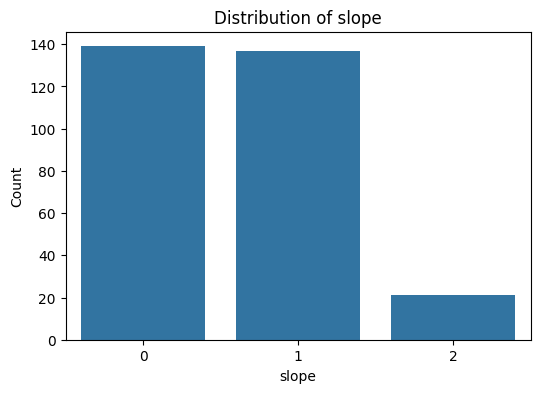

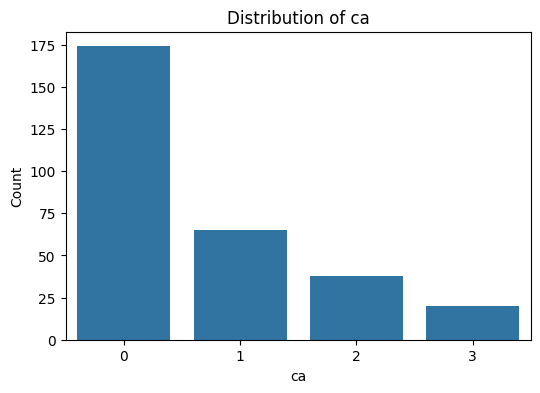

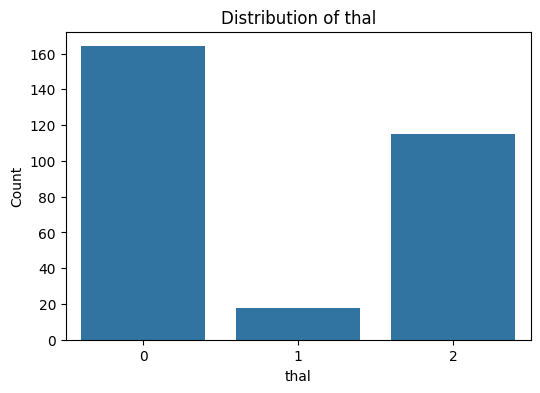

In [ ]:
cat_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

for col in cat_features:
    plt.figure(figsize=(6,4))
    sns.countplot(data=df, x=col)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

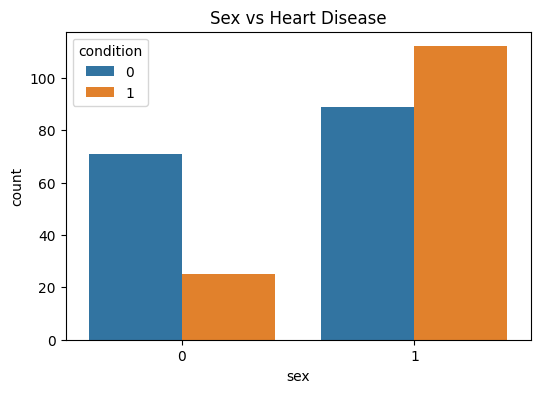

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='sex', hue='condition')
plt.title('Sex vs Heart Disease')
plt.show()

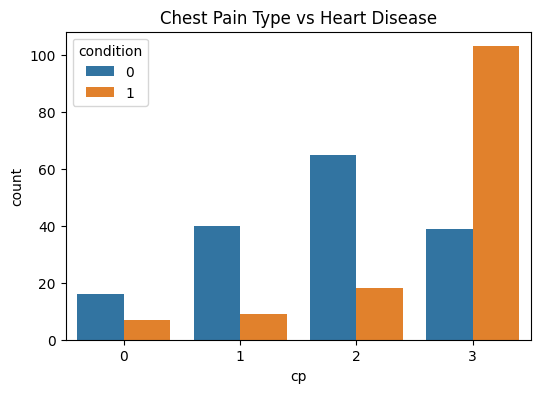

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='cp', hue='condition')
plt.title('Chest Pain Type vs Heart Disease')
plt.show()

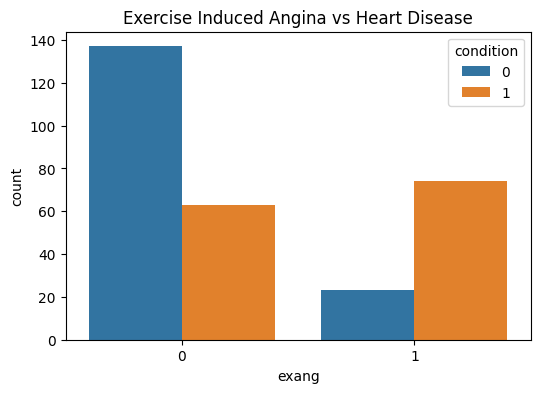

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='exang', hue='condition')
plt.title('Exercise Induced Angina vs Heart Disease')
plt.show()

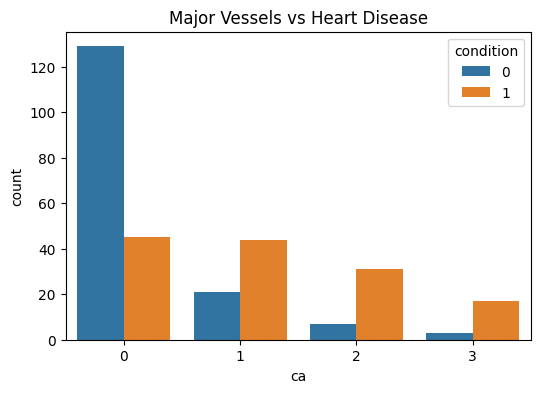

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='ca', hue='condition')
plt.title('Major Vessels vs Heart Disease')
plt.show()

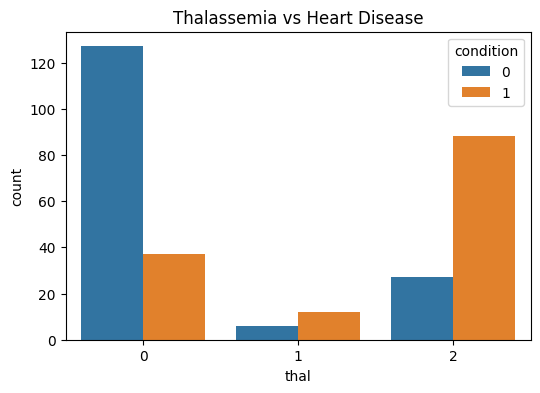

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='thal', hue='condition')
plt.title('Thalassemia vs Heart Disease')
plt.show()

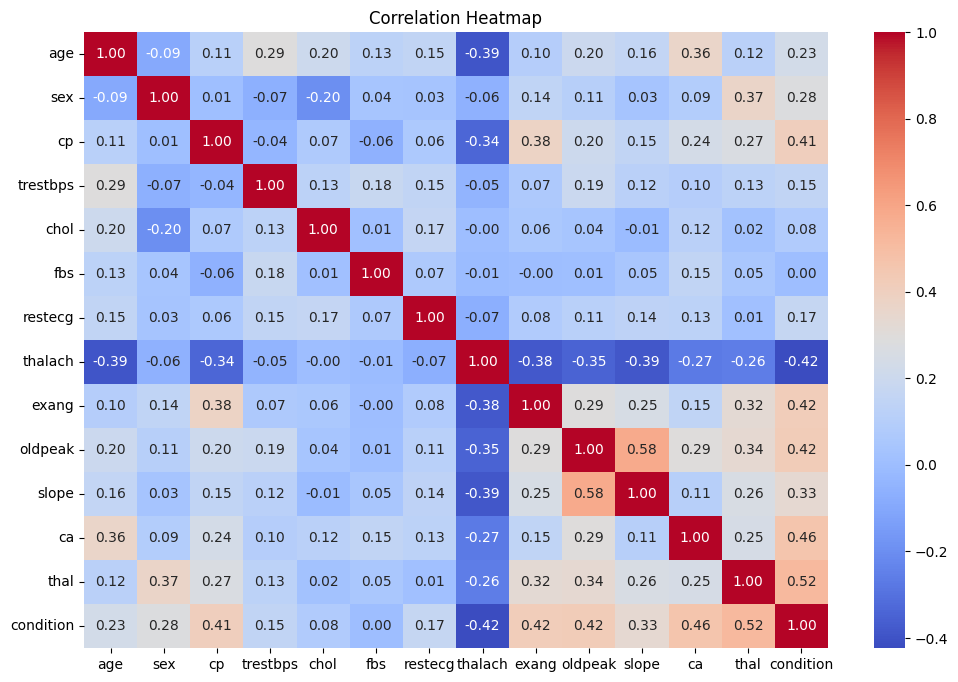

In [ ]:
plt.figure(figsize=(12,8))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Correlation Heatmap")

plt.show()

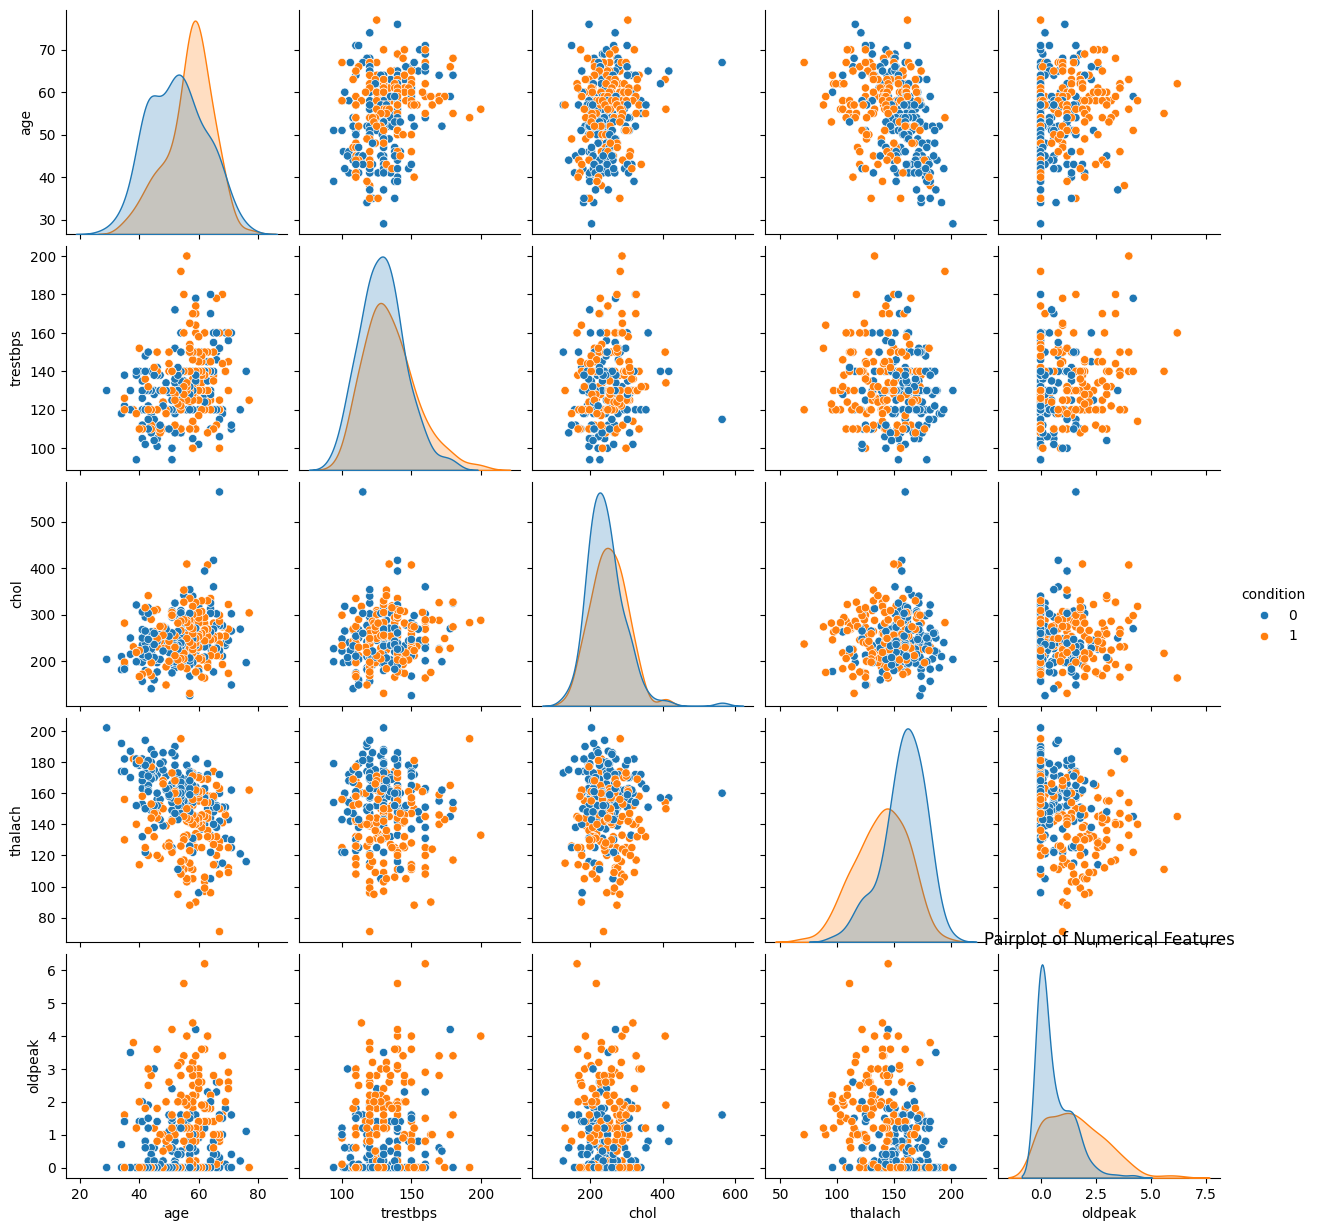

In [ ]:
sns.pairplot(
    df[['age','trestbps','chol','thalach','oldpeak','condition']],
    hue='condition'
)

plt.title("Pairplot of Numerical Features")
plt.show()

In [ ]:
df['condition'].value_counts()

,count
condition,
0,160
1,137


In [ ]:
df['condition'].value_counts(normalize=True) * 100

,proportion
condition,
0,53.872054
1,46.127946


#Trian-Test split


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
print("Training Features :", X_train.shape)
print("Testing Features :", X_test.shape)

print("Training Labels :", y_train.shape)
print("Testing Labels :", y_test.shape)

Training Features : (237, 13)
Testing Features : (60, 13)
Training Labels : (237,)
Testing Labels : (60,)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [ ]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(237, 13)
(60, 13)


#Model building


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Support Vector Machine": SVC(probability=True, random_state=42)
}

In [ ]:
results = {}

for name, model in models.items():

    if name in ["Logistic Regression", "KNN", "Support Vector Machine","Decison Tree","Random Forest"]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:,1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:,1]

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_prob)
    }

#Model comparison

In [ ]:
results_df = pd.DataFrame(results).T

results_df

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Logistic Regression,0.916667,1.000000,0.821429,0.901961,0.953125
KNN,0.900000,1.000000,0.785714,0.880000,0.959263
Decision Tree,0.783333,0.800000,0.714286,0.754717,0.779018
Random Forest,0.883333,0.956522,0.785714,0.862745,0.944754
Support Vector Machine,0.900000,1.000000,0.785714,0.880000,0.939732


In [ ]:
results_df.sort_values(by="Accuracy", ascending=False)

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Logistic Regression,0.916667,1.000000,0.821429,0.901961,0.953125
KNN,0.900000,1.000000,0.785714,0.880000,0.959263
Support Vector Machine,0.900000,1.000000,0.785714,0.880000,0.939732
Random Forest,0.883333,0.956522,0.785714,0.862745,0.944754
Decision Tree,0.783333,0.800000,0.714286,0.754717,0.779018


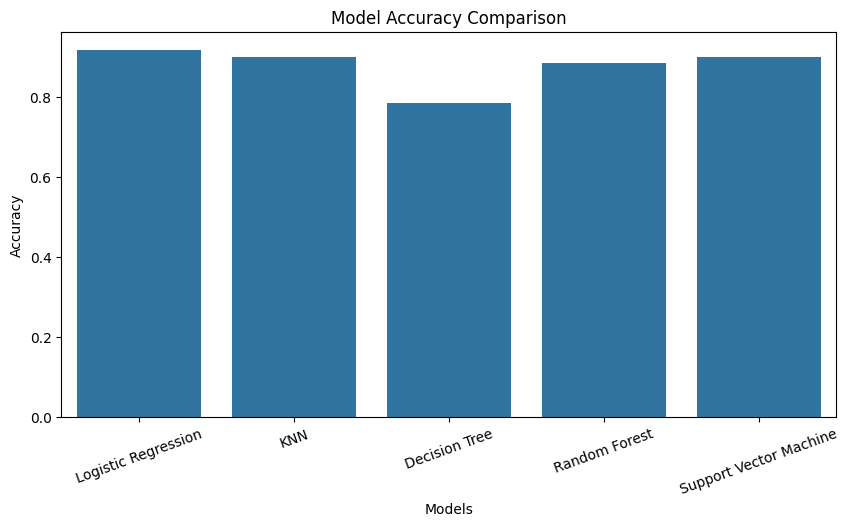

In [ ]:
plt.figure(figsize=(10,5))

sns.barplot(
    x=results_df.index,
    y=results_df['Accuracy']
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")

plt.xticks(rotation=20)

plt.show()

In [ ]:
results_df.style.background_gradient(cmap='Greens')

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Logistic Regression,0.916667,1.000000,0.821429,0.901961,0.953125
KNN,0.900000,1.000000,0.785714,0.880000,0.959263
Decision Tree,0.783333,0.800000,0.714286,0.754717,0.779018
Random Forest,0.883333,0.956522,0.785714,0.862745,0.944754
Support Vector Machine,0.900000,1.000000,0.785714,0.880000,0.939732


#Best model

In [ ]:
best_model_name = results_df["Accuracy"].idxmax()

print("Best Model:", best_model_name)


Best Model: Logistic Regression


In [ ]:
if best_model_name in ["Logistic Regression", "KNN", "Support Vector Machine","Decision Tree","Random Forest"]:
    y_pred = best_model.predict(X_test_scaled)
    y_prob = best_model.predict_proba(X_test_scaled)[:, 1]
else:
    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]

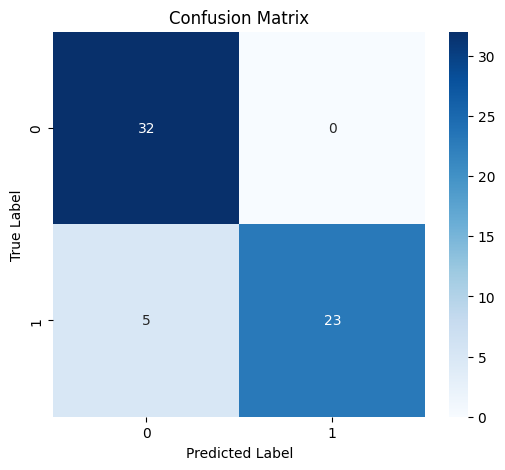

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      1.00      0.93        32
           1       1.00      0.82      0.90        28

    accuracy                           0.92        60
   macro avg       0.93      0.91      0.91        60
weighted avg       0.93      0.92      0.92        60



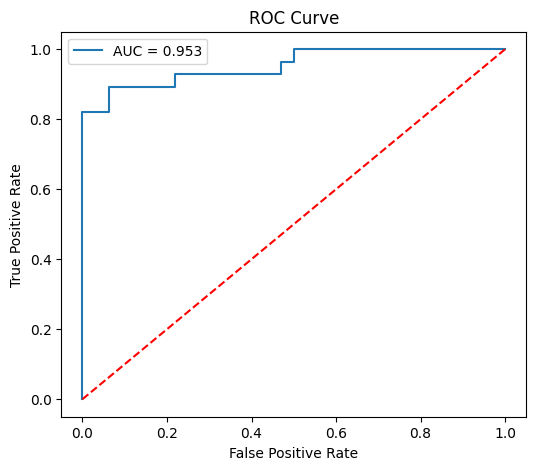

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6,5))

plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")

plt.plot([0,1],[0,1],'r--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.show()

#Hyperparameter Tuning

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 5, 10, 15],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 300]},
             scoring='accuracy')

In [ ]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation Score:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}

Best Cross Validation Score:
0.8233156028368794


In [ ]:
best_rf = grid_search.best_estimator_

In [ ]:
from sklearn.metrics import accuracy_score

y_pred = best_rf.predict(X_test)

print("Test Accuracy:")
print(accuracy_score(y_test, y_pred))

Test Accuracy:
0.85


#Feature Importance

In [113]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

,Feature,Importance
2,cp,0.152347
7,thalach,0.140957
11,ca,0.136344
9,oldpeak,0.128538
12,thal,0.120784
0,age,0.078871
8,exang,0.068362
4,chol,0.051386
3,trestbps,0.047802
10,slope,0.038037


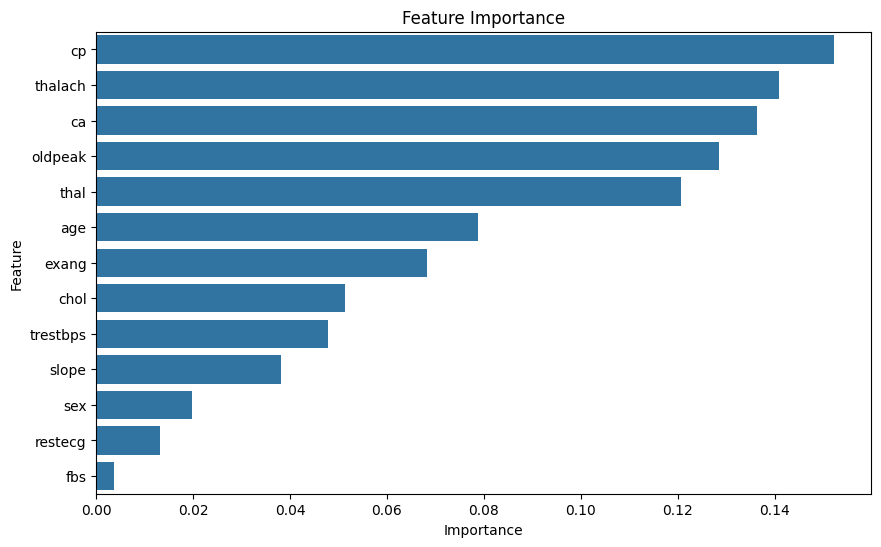

In [114]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title("Feature Importance")
plt.show()

#Saving the model


In [115]:
import joblib

joblib.dump(best_rf, 'heart_disease_model.pkl')

print("Model Saved Successfully!")

Model Saved Successfully!


#Conclusion

#In this project, a Heart Disease Prediction system was developed using multiple machine learning algorithms. After preprocessing the data and performing exploratory data analysis, five classification models were trained and evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC. The best-performing model was further optimized using hyperparameter tuning. The final model demonstrated strong predictive performance and can assist in identifying patients at risk of heart disease. This project showcases a complete end-to-end machine learning workflow, from data preparation to model deployment readiness.